# 🩺 ECG 심전도 부정맥 분류 AI (개선판)
### MIT-BIH Arrhythmia Dataset · 1D CNN · SMOTE + 클래스 가중치 적용

**개선 사항**
- ✅ SMOTE 오버샘플링으로 클래스 불균형 해소
- ✅ 클래스 가중치 손실함수 적용
- ✅ Dropout + BatchNorm으로 과적합 방지
- ✅ Early Stopping으로 최적 모델 자동 저장
- ✅ ROC-AUC, Macro F1 등 의료 지표 추가
- ✅ 정확한 클래스 명칭 사용 (Supravent, Ventricu)

In [1]:
# ── 셀 1: 라이브러리 설치 ──────────────────────────────────────
!pip install monai SimpleITK pydicom nibabel scikit-learn pandas matplotlib seaborn imbalanced-learn

Looking in indexes: https://pypi.org/simple, https://pypi.ngc.nvidia.com
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 2.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 10.5 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.8/52.8 MB 10.4 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 10.1 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 9.9 MB/s eta 0:00:00ta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.9/294.9 kB 10.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 235.4/235.4 kB 10.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 9.8 MB/s eta 0:00:0000:0100:01m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.2/18.2 MB 9.9 MB/s eta 0:00:0000:0100:01m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 532.1/532.1 MB 9.2 MB/s eta 0:00:0000:

In [2]:
# ── 셀 2: 임포트 ──────────────────────────────────────────────
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from imblearn.over_sampling import SMOTE
from torch.utils.data import TensorDataset, DataLoader

print(f'✅ PyTorch 버전: {torch.__version__}')
print(f'✅ GPU 사용 가능: {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'✅ GPU: {torch.cuda.get_device_name(0)}')

✅ PyTorch 버전: 2.12.0+cu130
✅ GPU 사용 가능: True
✅ GPU: NVIDIA GeForce RTX 2070


In [3]:
# ── 셀 3: 연습용 가상 데이터 생성 ────────────────────────────
# 실제 데이터 로드 전 모델 구조 테스트용입니다.
num_samples = 10000
signal_len = 187

t = np.linspace(0, 1, signal_len)
normal_wave    = np.sin(2 * np.pi * 5 * t)
abnormal_wave  = np.sin(2 * np.pi * 5 * t) + 0.5 * np.sin(2 * np.pi * 20 * t)

X_data, y_data = [], []
for _ in range(num_samples // 2):
    X_data.append(normal_wave   + np.random.normal(0, 0.1, signal_len))
    y_data.append(0)
    X_data.append(abnormal_wave + np.random.normal(0, 0.1, signal_len))
    y_data.append(1)

X = torch.tensor(np.array(X_data), dtype=torch.float32).unsqueeze(1).cuda()
y = torch.tensor(np.array(y_data), dtype=torch.float32).unsqueeze(1).cuda()

print(f'✅ 가상 데이터 준비 완료: {X.shape}')

✅ 가상 데이터 준비 완료: torch.Size([10000, 1, 187])


In [4]:
# ── 셀 4: 연습용 간단 모델 정의 및 학습 ─────────────────────
class ECG1DCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(1, 32, kernel_size=5, padding=2), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(32, 64, kernel_size=5, padding=2), nn.ReLU(), nn.MaxPool1d(2)
        )
        self.classifier = nn.Sequential(
            nn.Linear(64 * 46, 128), nn.ReLU(),
            nn.Linear(128, 1), nn.Sigmoid()
        )
    def forward(self, x):
        return self.classifier(self.features(x).view(x.size(0), -1))

simple_model = ECG1DCNN().cuda()
criterion_simple = nn.BCELoss()
optimizer_simple = optim.Adam(simple_model.parameters(), lr=0.001)

print('🚀 연습용 모델 학습 시작...')
for epoch in range(50):
    simple_model.train()
    outputs = simple_model(X)
    loss = criterion_simple(outputs, y)
    optimizer_simple.zero_grad(); loss.backward(); optimizer_simple.step()
    if (epoch + 1) % 10 == 0:
        print(f'Epoch [{epoch+1}/50], Loss: {loss.item():.4f}')

print('✅ 연습용 모델 학습 완료!')

🚀 연습용 모델 학습 시작...
Epoch [10/50], Loss: 0.2578
Epoch [20/50], Loss: 0.0069
Epoch [30/50], Loss: 0.0002
Epoch [40/50], Loss: 0.0000
Epoch [50/50], Loss: 0.0000
✅ 연습용 모델 학습 완료!


In [5]:
# ── 셀 5: 연습용 모델 저장 ───────────────────────────────────
torch.save(simple_model.state_dict(), '/workspace/medical_datasets/ecg_model_v1.pth')
print('💾 연습용 모델 저장 완료')

💾 연습용 모델 저장 완료


---
## 🏥 실전: MIT-BIH 실제 데이터로 학습

| 라벨 | 클래스명 | 의미 |
|------|----------|------|
| 0 (N) | Normal | 정상 박동 |
| 1 (S) | Supraventricular | 상심실성 이상 박동 |
| 2 (V) | Ventricular | 심실성 이상 박동 |
| 3 (F) | Fusion | 정상 + 심실 박동이 동시에 발생 |
| 4 (Q) | Unclassifiable | 분류 불가 박동 |

📂 MIT-BIH 데이터 로드 중...
✅ 로드 완료! 총 87,554개 샘플

📊 클래스 분포:
  Normal(N): 72,471개 (82.8%)
  Supravent(S): 2,223개 (2.5%)
  Ventricu(V): 5,788개 (6.6%)
  Fusion(F): 641개 (0.7%)
  Unclassifiable(Q): 6,431개 (7.3%)


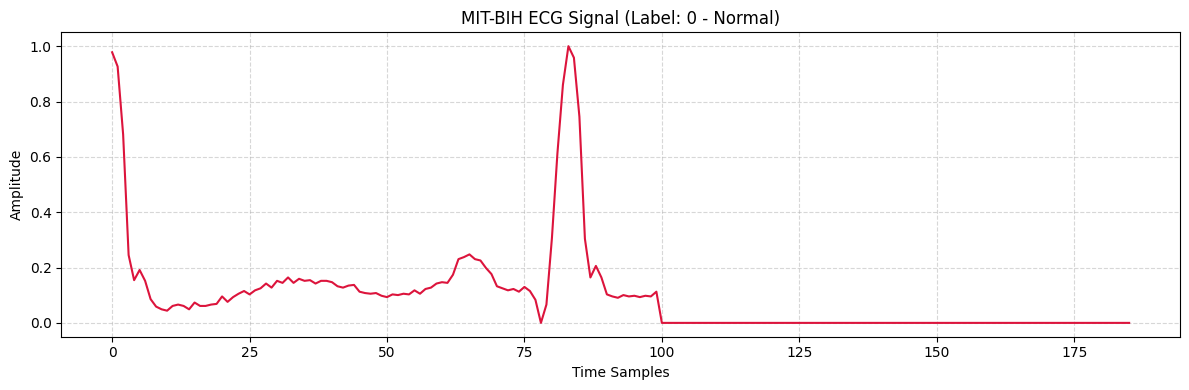

In [6]:
# ── 셀 6: 실제 데이터 로드 및 시각화 ────────────────────────
real_data_path = '/workspace/medical_datasets/share/archive/mitbih_train.csv'

print('📂 MIT-BIH 데이터 로드 중...')
df = pd.read_csv(real_data_path, header=None)
print(f'✅ 로드 완료! 총 {df.shape[0]:,}개 샘플')

# 클래스 분포 확인
class_names = ['Normal(N)', 'Supravent(S)', 'Ventricu(V)', 'Fusion(F)', 'Unclassifiable(Q)']
label_counts = df.iloc[:, 187].value_counts().sort_index()
print('\n📊 클래스 분포:')
for i, (label, count) in enumerate(zip(class_names, label_counts)):
    pct = count / len(df) * 100
    print(f'  {label}: {count:,}개 ({pct:.1f}%)')

# 심전도 신호 시각화
plt.figure(figsize=(12, 4))
plt.plot(df.iloc[0, :186], color='crimson', linewidth=1.5)
plt.title(f'MIT-BIH ECG Signal (Label: {int(df.iloc[0, 187])} - Normal)')
plt.xlabel('Time Samples'); plt.ylabel('Amplitude')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout(); plt.show()

In [7]:
# ── 셀 7: 데이터 분리 ────────────────────────────────────────
X_real = df.iloc[:, :186].values   # 신호 (0~185번 열)
y_real = df.iloc[:, 187].values.astype(int)  # 라벨 (187번 열)

# 학습(80%) / 검증(20%) 분리
# ⚠️ SMOTE는 학습 데이터에만 적용하므로 분리를 먼저 합니다
X_train, X_val, y_train, y_val = train_test_split(
    X_real, y_real, test_size=0.2, random_state=42, stratify=y_real
)

print(f'✅ 학습 데이터: {X_train.shape[0]:,}개')
print(f'✅ 검증 데이터: {X_val.shape[0]:,}개')

✅ 학습 데이터: 70,043개
✅ 검증 데이터: 17,511개


In [8]:
# ── 셀 8: SMOTE 오버샘플링 (핵심 개선!) ─────────────────────
# 문제: Fusion(F)이 전체의 0.8%뿐 → AI가 정상만 외쳐도 83% 정확도
# 해결: 소수 클래스 데이터를 인위적으로 늘려서 균형을 맞춤

print('⚙️  SMOTE 오버샘플링 적용 중...')
print(f'   적용 전 학습 데이터: {X_train.shape[0]:,}개')

# ⚠️ SMOTE는 numpy 2D 배열에 적용 (텐서 변환 전에 해야 함!)
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print(f'   적용 후 학습 데이터: {X_train_res.shape[0]:,}개')
print('\n📊 SMOTE 적용 후 클래스 분포:')
for i, name in enumerate(class_names):
    count = (y_train_res == i).sum()
    print(f'  {name}: {count:,}개')

⚙️  SMOTE 오버샘플링 적용 중...
   적용 전 학습 데이터: 70,043개
   적용 후 학습 데이터: 289,885개

📊 SMOTE 적용 후 클래스 분포:
  Normal(N): 57,977개
  Supravent(S): 57,977개
  Ventricu(V): 57,977개
  Fusion(F): 57,977개
  Unclassifiable(Q): 57,977개


In [9]:
# ── 셀 9: 텐서 변환 및 DataLoader 생성 ──────────────────────
# SMOTE 후 numpy → 텐서 변환, 채널 차원 추가: (N,186) → (N,1,186)

train_dataset = TensorDataset(
    torch.tensor(X_train_res, dtype=torch.float32).unsqueeze(1),
    torch.tensor(y_train_res, dtype=torch.long)
)
val_dataset = TensorDataset(
    torch.tensor(X_val, dtype=torch.float32).unsqueeze(1),
    torch.tensor(y_val, dtype=torch.long)
)

train_loader = DataLoader(train_dataset, batch_size=512, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_dataset,   batch_size=512, shuffle=False, num_workers=0)

print(f'✅ DataLoader 준비 완료!')
print(f'   학습 배치 수: {len(train_loader)}, 검증 배치 수: {len(val_loader)}')

✅ DataLoader 준비 완료!
   학습 배치 수: 567, 검증 배치 수: 35


In [10]:
# ── 셀 10: 개선된 모델 정의 ──────────────────────────────────
class RealECGNet(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(1, 32, kernel_size=5, padding=2),
            nn.BatchNorm1d(32),   # 학습 안정화
            nn.ReLU(),
            nn.MaxPool1d(2),

            nn.Conv1d(32, 64, kernel_size=5, padding=2),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(2)
        )
        self.classifier = nn.Sequential(
            nn.Linear(64 * 46, 128),
            nn.ReLU(),
            nn.Dropout(0.3),      # 과적합 방지
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x).view(x.size(0), -1))


# ── 클래스 가중치: 희귀 클래스를 틀리면 더 크게 패널티 ──────
# SMOTE 후에도 추가 보험으로 적용합니다
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train_res),
    y=y_train_res
)
weights_tensor = torch.tensor(class_weights, dtype=torch.float32).cuda()

model     = RealECGNet().cuda()
criterion = nn.CrossEntropyLoss(weight=weights_tensor)  # 가중치 적용!
optimizer = optim.Adam(model.parameters(), lr=0.001)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.5)  # LR 스케줄러

print('✅ 개선된 모델 준비 완료!')
print(f'   클래스 가중치: {dict(zip(class_names, class_weights.round(3)))}')

✅ 개선된 모델 준비 완료!
   클래스 가중치: {'Normal(N)': 1.0, 'Supravent(S)': 1.0, 'Ventricu(V)': 1.0, 'Fusion(F)': 1.0, 'Unclassifiable(Q)': 1.0}


In [11]:
# ── 셀 11: 학습 루프 + Early Stopping ───────────────────────
epochs        = 30
best_val_loss = float('inf')
patience      = 5       # 5 에폭 연속 개선 없으면 조기 종료
patience_cnt  = 0
best_path     = '/workspace/medical_datasets/share/archive/mitbih_ecg_best.pth'
train_losses, val_losses = [], []

print('🚀 학습 시작!')

for epoch in range(epochs):
    # ── 학습 단계 ────────────────────────────────────────────
    model.train()
    total_train_loss = 0
    for batch_X, batch_y in train_loader:
        batch_X, batch_y = batch_X.cuda(), batch_y.cuda()
        loss = criterion(model(batch_X), batch_y)
        optimizer.zero_grad(); loss.backward(); optimizer.step()
        total_train_loss += loss.item()

    # ── 검증 단계 ────────────────────────────────────────────
    model.eval()
    total_val_loss = 0
    with torch.no_grad():
        for batch_X, batch_y in val_loader:
            batch_X, batch_y = batch_X.cuda(), batch_y.cuda()
            total_val_loss += criterion(model(batch_X), batch_y).item()

    avg_train = total_train_loss / len(train_loader)
    avg_val   = total_val_loss   / len(val_loader)
    train_losses.append(avg_train)
    val_losses.append(avg_val)

    print(f'Epoch [{epoch+1:02d}/{epochs}]  Train Loss: {avg_train:.4f}  Val Loss: {avg_val:.4f}')

    # ── Early Stopping 체크 ──────────────────────────────────
    if avg_val < best_val_loss:
        best_val_loss = avg_val
        torch.save(model.state_dict(), best_path)
        patience_cnt = 0
        print(f'   💾 Best 모델 저장! (Val Loss: {best_val_loss:.4f})')
    else:
        patience_cnt += 1
        if patience_cnt >= patience:
            print(f'\n⛔ Early Stopping! ({patience} 에폭 동안 개선 없음)')
            break

    scheduler.step()

print('\n✅ 학습 완료!')

🚀 학습 시작!
Epoch [01/30]  Train Loss: 0.1585  Val Loss: 0.1700
   💾 Best 모델 저장! (Val Loss: 0.1700)
Epoch [02/30]  Train Loss: 0.0551  Val Loss: 0.1025
   💾 Best 모델 저장! (Val Loss: 0.1025)
Epoch [03/30]  Train Loss: 0.0359  Val Loss: 0.1689
Epoch [04/30]  Train Loss: 0.0267  Val Loss: 0.0878
   💾 Best 모델 저장! (Val Loss: 0.0878)
Epoch [05/30]  Train Loss: 0.0229  Val Loss: 0.0889
Epoch [06/30]  Train Loss: 0.0119  Val Loss: 0.0857
   💾 Best 모델 저장! (Val Loss: 0.0857)
Epoch [07/30]  Train Loss: 0.0101  Val Loss: 0.0928
Epoch [08/30]  Train Loss: 0.0090  Val Loss: 0.0957
Epoch [09/30]  Train Loss: 0.0086  Val Loss: 0.0998
Epoch [10/30]  Train Loss: 0.0081  Val Loss: 0.1037
Epoch [11/30]  Train Loss: 0.0048  Val Loss: 0.1019

⛔ Early Stopping! (5 에폭 동안 개선 없음)

✅ 학습 완료!


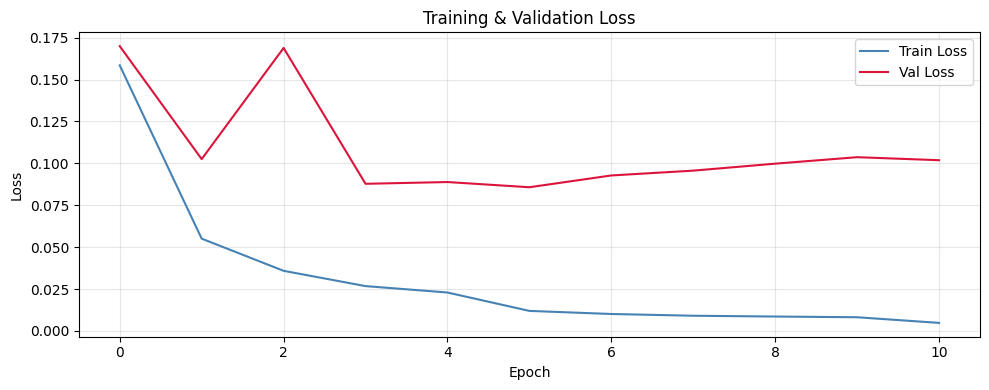

In [12]:
# ── 셀 12: 학습 곡선 시각화 ──────────────────────────────────
plt.figure(figsize=(10, 4))
plt.plot(train_losses, label='Train Loss', color='steelblue')
plt.plot(val_losses,   label='Val Loss',   color='crimson')
plt.title('Training & Validation Loss')
plt.xlabel('Epoch'); plt.ylabel('Loss')
plt.legend(); plt.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

In [13]:
# ── 셀 13: 최종 모델 저장 ────────────────────────────────────
final_path = '/workspace/medical_datasets/share/archive/mitbih_ecg_model_final.pth'
torch.save(model.state_dict(), final_path)
print(f'💾 최종 모델 저장: {final_path}')
print(f'💾 Best 모델 저장: {best_path}')

💾 최종 모델 저장: /workspace/medical_datasets/share/archive/mitbih_ecg_model_final.pth
💾 Best 모델 저장: /workspace/medical_datasets/share/archive/mitbih_ecg_best.pth


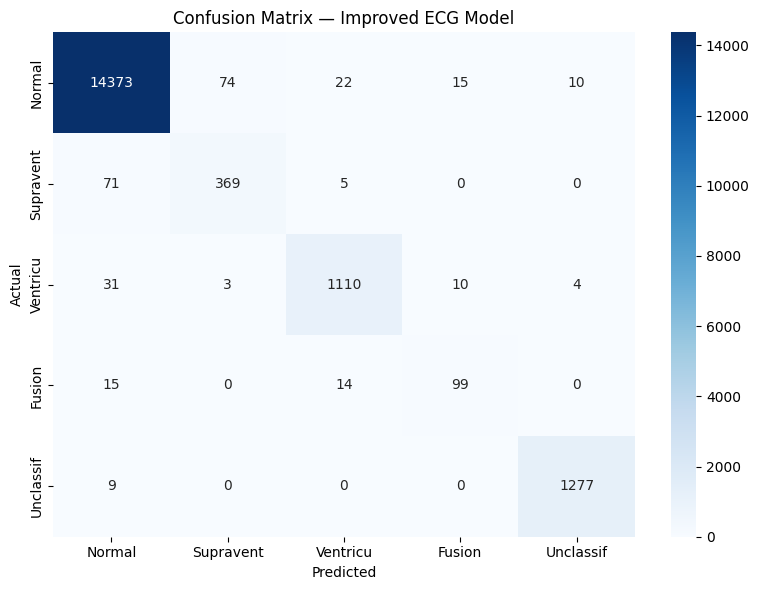


--- 🩺 [개선판] AI 의공학 진단 성적표 ---
              precision    recall  f1-score   support

      Normal       0.99      0.99      0.99     14494
   Supravent       0.83      0.83      0.83       445
    Ventricu       0.96      0.96      0.96      1158
      Fusion       0.80      0.77      0.79       128
   Unclassif       0.99      0.99      0.99      1286

    accuracy                           0.98     17511
   macro avg       0.91      0.91      0.91     17511
weighted avg       0.98      0.98      0.98     17511

ROC-AUC Score (OvR): 0.9927


In [14]:
# ── 셀 14: 성능 평가 ─────────────────────────────────────────
# Best 모델을 불러와서 평가합니다
model.load_state_dict(torch.load(best_path))
model.eval()

all_preds, all_labels, all_probs = [], [], []

with torch.no_grad():
    for batch_X, batch_y in val_loader:
        outputs = model(batch_X.cuda())
        probs   = torch.softmax(outputs, dim=1)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(batch_y.numpy())
        all_probs.extend(probs.cpu().numpy())

all_preds  = np.array(all_preds)
all_labels = np.array(all_labels)
all_probs  = np.array(all_probs)

# ── 혼동 행렬 ────────────────────────────────────────────────
label_display = ['Normal', 'Supravent', 'Ventricu', 'Fusion', 'Unclassif']
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_display, yticklabels=label_display)
plt.title('Confusion Matrix — Improved ECG Model')
plt.ylabel('Actual'); plt.xlabel('Predicted')
plt.tight_layout(); plt.show()

# ── 분류 리포트 ──────────────────────────────────────────────
print('\n--- 🩺 [개선판] AI 의공학 진단 성적표 ---')
print(classification_report(all_labels, all_preds, target_names=label_display))

# ── ROC-AUC ──────────────────────────────────────────────────
auc = roc_auc_score(all_labels, all_probs, multi_class='ovr')
print(f'ROC-AUC Score (OvR): {auc:.4f}')